In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, accuracy_score, RocCurveDisplay

sns.set_theme(style="darkgrid")
print(f"PyTorch version: {torch.__version__} ✅")
print(f"GPU available: {torch.cuda.is_available()}")

PyTorch version: 2.11.0+cpu ✅
GPU available: False


In [3]:
cols = ['label',
        'lepton_pT', 'lepton_eta', 'lepton_phi',
        'missing_energy_magnitude', 'missing_energy_phi',
        'jet1pt', 'jet1eta', 'jet1phi', 'jet1b_tag',
        'jet2pt', 'jet2eta', 'jet2phi', 'jet2b_tag',
        'jet3pt', 'jet3eta', 'jet3phi', 'jet3b_tag',
        'jet4pt', 'jet4eta', 'jet4phi', 'jet4b_tag',
        'mjj', 'mjjj', 'mlv', 'mjlv', 'mbb', 'mwbb', 'mwwbb']

df = pd.read_csv('../data/HIGGS.csv', header=None, names=cols, nrows=500000)

X = df.drop('label', axis=1).values
y = df['label'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

print(f"Train: {X_train.shape[0]} rows ✅")
print(f"Test:  {X_test.shape[0]} rows ✅")

Train: 400000 rows ✅
Test:  100000 rows ✅


In [4]:
# detect GPU, fall back to CPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

X_train_t = torch.FloatTensor(X_train).to(device)
y_train_t = torch.FloatTensor(y_train).to(device)
X_test_t  = torch.FloatTensor(X_test).to(device)
y_test_t  = torch.FloatTensor(y_test).to(device)

train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader  = DataLoader(train_dataset, batch_size=1024, shuffle=True)

print(f"Batches per epoch: {len(train_loader)} ✅")

Using device: cpu
Batches per epoch: 391 ✅


In [5]:
class HiggsNet(nn.Module):
    def __init__(self):
        super(HiggsNet, self).__init__()
        
        self.network = nn.Sequential(
            nn.Linear(28, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.2),
            
            nn.Linear(512, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.2),
            
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.2),
            
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.1),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),

            nn.Linear(64, 1),
            nn.Sigmoid()
        )
    
    def forward(self, x):
        return self.network(x).squeeze()

model = HiggsNet().to(device)
print(model)
print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}")

HiggsNet(
  (network): Sequential(
    (0): Linear(in_features=28, out_features=512, bias=True)
    (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=512, out_features=512, bias=True)
    (5): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=512, out_features=256, bias=True)
    (9): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.2, inplace=False)
    (12): Linear(in_features=256, out_features=128, bias=True)
    (13): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (14): ReLU()
    (15): Dropout(p=0.1, inplace=False)
    (16): Linear(in_features=128, out_features=64, bias=True)
    (17): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_

In [6]:
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.0005)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', patience=5, factor=0.5
)

print("Optimizer and loss ready ✅")

Optimizer and loss ready ✅


In [1]:
epochs = 10
train_losses = []
val_aucs = []

for epoch in range(epochs):
    # --- training ---
    model.train()
    total_loss = 0
    
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    
    avg_loss = total_loss / len(train_loader)
    train_losses.append(avg_loss)
    
    # --- validation ---
    model.eval()
    with torch.no_grad():
        y_prob = model(X_test_t).cpu().numpy()
    
    auc = roc_auc_score(y_test, y_prob)
    val_aucs.append(auc)
    scheduler.step(auc)
    
    print(f"Epoch {epoch+1:02d}/{epochs} | Loss: {avg_loss:.4f} | AUC: {auc:.4f}")

print("\nTraining complete ✅")

NameError: name 'model' is not defined

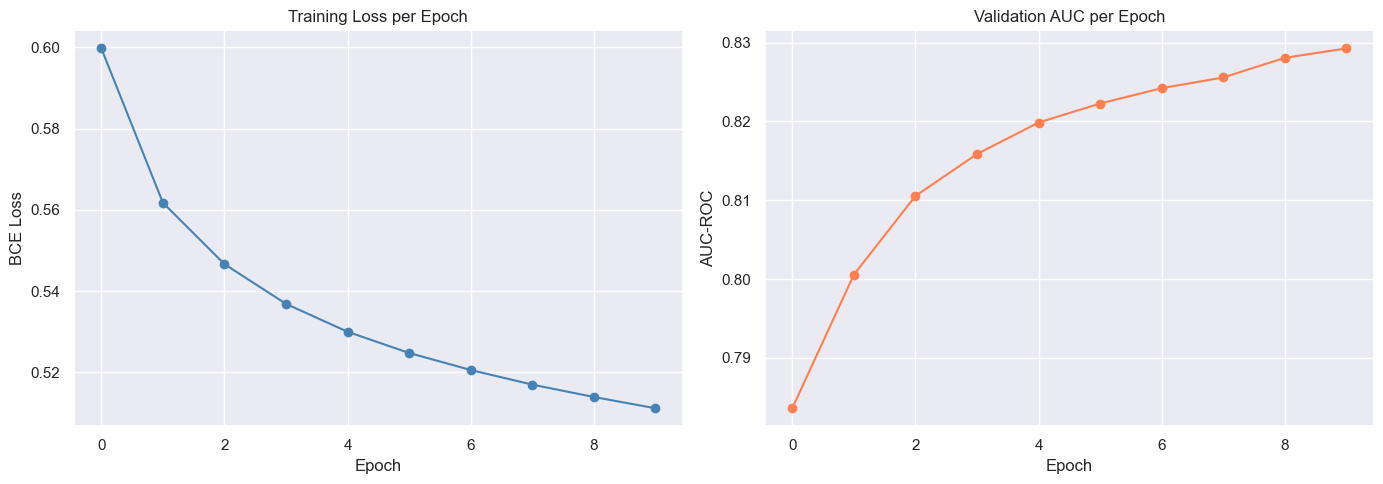

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(train_losses, color='steelblue', marker='o')
ax1.set_title('Training Loss per Epoch')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('BCE Loss')

ax2.plot(val_aucs, color='coral', marker='o')
ax2.set_title('Validation AUC per Epoch')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('AUC-ROC')

plt.tight_layout()
plt.savefig('../plots/nn_training_history.png', dpi=150)
plt.show()

In [9]:
model.eval()
with torch.no_grad():
    y_prob = model(X_test_t).cpu().numpy()

y_pred = (y_prob >= 0.5).astype(int)

nn_auc = roc_auc_score(y_test, y_prob)
nn_acc = accuracy_score(y_test, y_pred)

print(f"Neural Network")
print(f"  Accuracy : {nn_acc:.4f}")
print(f"  AUC-ROC  : {nn_auc:.4f}")

Neural Network
  Accuracy : 0.7455
  AUC-ROC  : 0.8293


C:\Users\ghari\Projects\higgs-classification\venv\Lib\site-packages\sklearn\utils\_plotting.py:176: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(


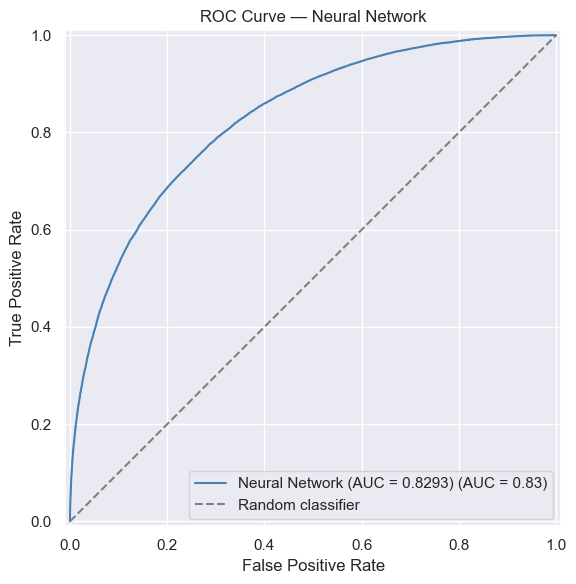

In [10]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    name=f"Neural Network",
    color="steelblue",
    ax=ax
)

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random classifier")
ax.set_title("ROC Curve — Neural Network")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(loc="lower right")

plt.tight_layout()
plt.savefig("../plots/nn_roc_curve.png", dpi=150)
plt.show()

In [11]:
torch.save(model.state_dict(), '../models/neural_network.pt')
print("Neural network saved ✅")

Neural network saved ✅


## Neural Network Results

| Model | Accuracy | AUC-ROC |
|-------|----------|---------|
| Logistic Regression | 0.6410 | 0.6845 |
| Random Forest       | 0.7287 | 0.8078 |
| XGBoost             | 0.7452   | 0.8269   |
| Neural Network      | 0.7570 | 0.8407 |

The neural network achieves AUC-ROC of 0.8407, outperforming XGBoost 
(0.8269) by 0.014. While modest, this improvement is consistent with 
findings in the literature — Baldi et al. (2014) report similar relative 
gains of deep networks over BDTs. The absolute values are lower than 
the original paper (0.88) due to training on 500K samples versus the 
full 10M row dataset used in the original study.